# Warm-up constructions

OpenSARShip2 · DenseNet-121 · Supplementary Note S4

Compare four warm-up inputs under the same training settings using five paired seeds.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/s4_family.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from gw import presentation as report
config = report.read_experiment(ROOT, 's4_family')
saved_evaluation = ROOT / 'results/s4_family/gpu_predictions'
runs = report.load_predictions(ROOT, config, saved_evaluation if (saved_evaluation / 'run.json').exists() else None)
mean, std = report.summarize(runs, config)
from gw.publication_ui import folded_table, folded_comparison, compact_settings

## Results

Validation · 954 images per run · 5 paired seeds. Percentages are used for ECE, accuracy and macro-F1; NLL and Brier are dimensionless.

In [2]:
report.show_table(mean)
gap = mean.loc['Gaussian', 'ECE (%)'] - mean.loc['GW', 'ECE (%)']
display(Markdown(f"**GW achieves {mean.loc['GW', 'ECE (%)']:.2f}% mean ECE**, compared with {mean.loc['Gaussian', 'ECE (%)']:.2f}% for Gaussian warm-up ({gap:.2f} percentage points lower)."))

,ECE (%),Accuracy (%),Macro-F1 (%),NLL,Brier
Method,,,,,
GW,5.14,65.7,47.5,0.80335,0.45951
Gaussian,6.83,65.5,44.2,0.80397,0.45983
Uniform,6.67,65.1,46.1,0.80662,0.45962
Laplace,5.71,65.6,48.5,0.80079,0.45937


**GW achieves 5.14% mean ECE**, compared with 6.83% for Gaussian warm-up (1.69 percentage points lower).

## Calibration

Diamonds show the mean, error bars the sample standard deviation, and small circles the five individual runs.

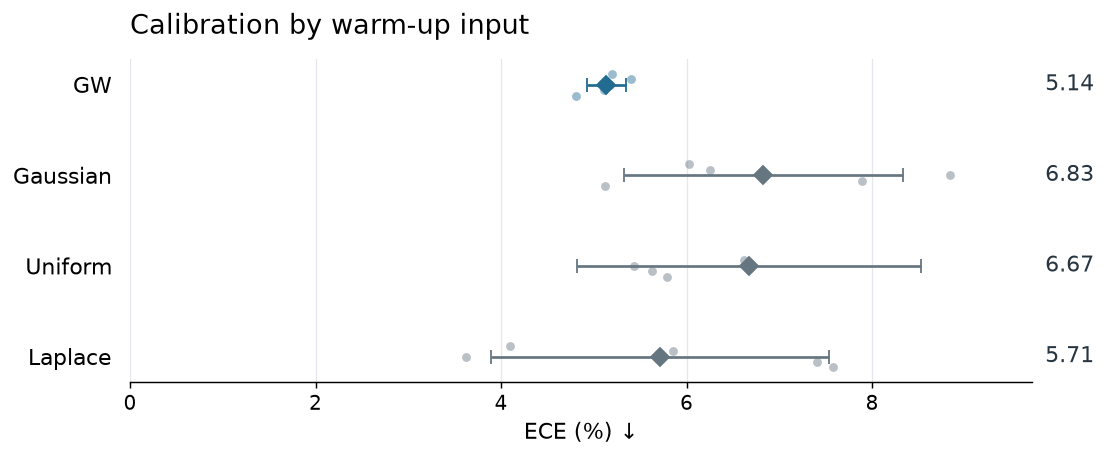

In [3]:
figure = report.calibration_plot(runs, mean, std, ROOT / 'assets/figures/s4_family_ece.png')
display(figure)
import matplotlib.pyplot as plt
plt.close(figure)

## Settings

In [4]:
display(report.settings(config))

,Value
Setting,
Dataset,OpenSARShip2
Model,DenseNet-121
Evaluation,Validation · 954 images
Runs per condition,5
Input,128 × 128 · grayscale
Warm-up,5 epochs
Supervised training,50 epochs
Gate probability,0.5
Strength,0.5


<details><summary>Seeds and configuration</summary>

Seeds: 20262001–20262005. [Complete configuration](../configs/s4_family.json).

</details>

## Reference values

In [5]:
comparison = report.paper_comparison(ROOT, config, mean)
full = comparison[['Method', 'Metric', 'Paper', 'Recomputed']].copy()
for column in ['Paper', 'Recomputed']:
    full[column] = [f'{value:.{report.PRECISION[metric]}f}' for value, metric in zip(full[column], full['Metric'])]
folded_comparison(full)

,Method,Metric,Paper,Recomputed
0,GW,ECE (%),5.14,5.14
1,GW,Accuracy (%),65.7,65.7
2,GW,Macro-F1 (%),47.5,47.5
3,GW,NLL,0.80335,0.80335
4,GW,Brier,0.45951,0.45951
5,Gaussian,ECE (%),6.83,6.83
6,Gaussian,Accuracy (%),65.5,65.5
7,Gaussian,Macro-F1 (%),44.2,44.2
8,Gaussian,NLL,0.80397,0.80397
9,Gaussian,Brier,0.45983,0.45983


## Inference

Set `RUN_INFERENCE = True` to evaluate the checkpoints.

In [6]:
RUN_INFERENCE = False
if RUN_INFERENCE:
    from gw.inference import run_family
    prediction_directory = run_family(ROOT, config)
    fresh_runs = report.load_predictions(ROOT, config, prediction_directory)
    fresh_mean, fresh_std = report.summarize(fresh_runs, config)
    report.show_table(fresh_mean)
    folded_comparison(report.paper_comparison(ROOT, config, fresh_mean))

## Training

Optional · one seed and condition · validation NLL selection. Set `RUN_TRAINING = True` to run.

In [7]:
import json
import pandas as pd
RUN_TRAINING = False
TRAIN_RUN = 'gw_20262001'

training_config = json.loads((ROOT / 'configs/ablation_training.json').read_text())
matches = [run for run in training_config['runs']
           if run['experiment'] == 's4_family' and run['id'] == TRAIN_RUN]
if len(matches) != 1:
    raise ValueError('Choose a run ID from configs/ablation_training.json')
selected_run = matches[0]
labels = {condition['id']: condition['label'] for condition in config['conditions']}
selection = pd.DataFrame([{
    'Condition': labels[selected_run['condition']],
    'Seed': selected_run['seed'],
    'Warm-up epochs': selected_run['warmup_epochs'],
    'Training epochs': selected_run['supervised_epochs']
}])
display(selection.style.hide(axis='index'))

if RUN_TRAINING:
    from gw.ablation_training import train
    training_directory = train(ROOT, selected_run, device='auto')
    training_record = json.loads((training_directory / 'run.json').read_text())
    validation = training_record['validation']
    result = pd.DataFrame([{'Seed': selected_run['seed'],
                            'Selected epoch': training_record['best_epoch'],
                            'ECE (%)': 100 * validation['ece_15'],
                            'NLL': validation['nll']}])
    display(result.style.hide(axis='index').format({'ECE (%)': '{:.2f}', 'NLL': '{:.4f}'}))
    print(training_directory)


Condition,Seed,Warm-up epochs,Training epochs
GW,20262001,5,50
